# EE 447 Final Project Report

<font color="gray">*This template is developed by Prof. Sep Makhsous and has been refined with the assistance of Gemini.*</font>

**Student:** <font>*Graham Rawson*</font>

**Selected plant:** <font>*Replace with plant number and title, e.g., Plant 4, Single-Inertia Rotary Positioner*</font>

**Physical application:** <font>*Replace with your application, e.g., rooftop directional-antenna pointing stage*</font>

This single Google Colab notebook serves as the complete project report submitted for Milestones 1, 2, and 3. All provided headings must be retained.

## How to Use This Template

1. Choose **File > Save a copy in Drive** before editing.
2. Rename the notebook `LastName_FirstName_EE447_FinalProject.ipynb`.
3. Complete only the sections required for the current milestone.
4. Keep equations, code, plots, numerical results, and interpretation together under their respective headings.
5. Delete the example proposal section (`# Example Milestone 1 Proposal`) before submitting your final Milestone 1 work.

# Example Milestone 1 Proposal

**Example only - do not copy this application or its numerical values.** This example demonstrates the expected specificity and organization for your milestone proposal.

### Example 1.1 - Plant Selection and Physical Application

The proposed system rotates a small directional antenna to a commanded azimuth angle. A geared electric motor applies torque to the antenna shaft, and an optical encoder measures shaft angle. Accurate pointing is needed because an angle error reduces received signal strength. Bearing friction, flexible cable routing, payload inertia, and wind torque limit performance. Feedback control moves the antenna to a new command, reduces final pointing error, and returns the antenna to the commanded angle after a wind gust. The nominal model includes antenna inertia, viscous bearing damping, and the torsional stiffness of the cable harness. Motor electrical dynamics and gear backlash are omitted from the nominal model and discussed as limitations.

*Physical-system image: Insert a labeled photograph or sketch showing the motor, shaft, antenna, encoder, cable harness, and wind direction. Add a caption and source.*

### Example 1.2 - System Boundary and Feedback Signals

The system utilizes negative feedback with the error definition:
$$e(t) = r(t) - y(t)$$

Where:
- $r(t)$: desired antenna azimuth angle, degrees, expected range $-90^\circ$ to $+90^\circ$, supplied by the operator.
- $u(t)$: motor torque applied to the shaft, N m, limited to $\pm5$ N m by the motor and drive.
- $y(t)$: measured antenna azimuth angle, degrees, measured by the shaft encoder.
- $d(t)$: wind torque, N m, acting directly on the rotating antenna inside the physical plant.

The nominal plant boundary includes the motor output shaft, antenna structure, bearings, payload inertia, and cable-harness stiffness. Motor electrical dynamics and gear backlash are outside the nominal model. Wind torque enters at the plant because wind acts directly on the antenna surface.

The system remains SISO because $u(t)$ is the only manipulated input. The wind torque $d(t)$ is an external disturbance, not a second control input. In this example, motor torque and wind torque combine to form the net torque acting on the antenna.

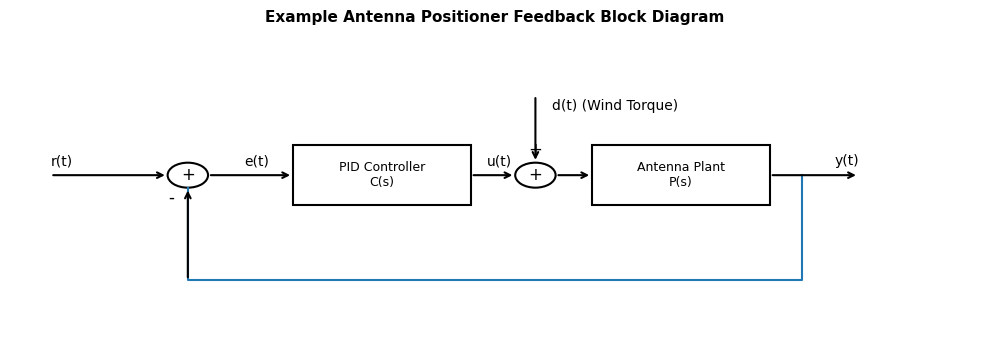

In [ ]:
# Import matplotlib to draw the feedback block diagram
import matplotlib.pyplot as plt

# NOTE: This disturbance location is specific to the wind torque acting directly on the antenna.
# Your own project must place and justify the disturbance location based on your physical system.

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.set_xlim(-1, 11)
ax.set_ylim(-2, 4)

# Draw blocks
ax.add_patch(plt.Rectangle((2.5, 0.5), 2.2, 1.2, fill=False, lw=1.5))
ax.text(3.6, 1.1, 'PID Controller\nC(s)', ha='center', va='center', fontsize=9)

ax.add_patch(plt.Rectangle((6.2, 0.5), 2.2, 1.2, fill=False, lw=1.5))
ax.text(7.3, 1.1, 'Antenna Plant\nP(s)', ha='center', va='center', fontsize=9)

# Summing junctions
ax.add_patch(plt.Circle((1.2, 1.1), 0.25, fill=False, lw=1.5))
ax.text(1.2, 1.1, '+', ha='center', va='center', fontsize=12)
ax.text(1.0, 0.65, '-', ha='center', va='center', fontsize=12)

ax.add_patch(plt.Circle((5.5, 1.1), 0.25, fill=False, lw=1.5))
ax.text(5.5, 1.1, '+', ha='center', va='center', fontsize=12)
ax.text(5.5, 1.6, '+', ha='center', va='center', fontsize=12)

# Signal lines and arrows
ax.annotate('', xy=(0.95, 1.1), xytext=(-0.5, 1.1), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(-0.5, 1.3, 'r(t)', fontsize=10)

ax.annotate('', xy=(2.5, 1.1), xytext=(1.45, 1.1), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(1.9, 1.3, 'e(t)', fontsize=10)

ax.annotate('', xy=(5.25, 1.1), xytext=(4.7, 1.1), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(4.9, 1.3, 'u(t)', fontsize=10)

ax.annotate('', xy=(6.2, 1.1), xytext=(5.75, 1.1), arrowprops=dict(arrowstyle="->", lw=1.5))

ax.annotate('', xy=(9.5, 1.1), xytext=(8.4, 1.1), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(9.2, 1.3, 'y(t)', fontsize=10)

# Disturbance
ax.annotate('', xy=(5.5, 1.35), xytext=(5.5, 2.7), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(5.7, 2.4, 'd(t) (Wind Torque)', fontsize=10)

# Feedback path
ax.plot([8.8, 8.8, 1.2, 1.2], [1.1, -1.0, -1.0, 0.85], lw=1.5)
ax.annotate('', xy=(1.2, 0.85), xytext=(1.2, -1.0), arrowprops=dict(arrowstyle="->", lw=1.5))

ax.set_axis_off()
plt.title('Example Antenna Positioner Feedback Block Diagram', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### Example 1.3 - Preliminary Control Requirements

- Command test: $30^\circ$ step in desired azimuth.
- Maximum 2% settling time: $T_s \leq 2.5$ s.
- Maximum overshoot: 5%.
- Maximum steady-state pointing error: $0.5^\circ$.
- Maximum actuator effort: $|u(t)| \leq 5$ N m.
- Disturbance test: apply a 1 N m step wind torque at the antenna at $t=5$ s; the angle must return to within $\pm0.5^\circ$ of the command within 2 s.

These preliminary targets will be verified for physical feasibility once the nominal plant parameters are established.

### Example 1.4 - Parameter Acquisition Plan

| Symbol | Physical meaning | Units | Acquisition method |
|---|---|---:|---|
| $J$ | Antenna and shaft inertia | kg m$^2$ | Estimate from measured component masses |
| $B$ | Equivalent viscous damping | N m s/rad | Estimate from free-decay test |
| $K$ | Cable-harness torsional stiffness | N m/rad | Measure applied torque vs static deflection |
| $\tau_{max}$ | Maximum motor torque | N m | Motor manufacturer datasheet |

Because inertia and torsional stiffness store energy, the nominal angle plant is expected to be a second-order physical system.

### Example 1.5 - Personalization and Feasibility

- **Personalization:** The project is personalized through the unique measured antenna geometry, custom cable-harness stiffness, and wind load based on the surface area of the specific antenna used.
- **Robustness:** The robustness test varies $J$ by $\pm25\%$ to represent different antenna attachments and payloads.
- **Feasibility Limits:** The final simulation explicitly evaluates the $\pm5$ N m motor torque limits and the physical $0.1^\circ$ encoder resolution limit.
- **Scope:** The project consists of a single input, one measured output, and a second-order nominal physical model, which directly fits the classical control project scope.

---
---

# Milestone 1 - Student Project Proposal

> *Note: Delete the example proposal section above once you have used it as a guide to complete your proposal below.*

## 1.1 - Plant Selection and Physical Application

- **Starting Plant Number and Title:** [Replace with starting plant number and title, e.g., Plant 2, Active Base-Isolation System]
- **Specific Real Device/Process:** [Replace with your application, e.g., Camera or sensor platform isolating vibration from a vehicle floor]

**Application Narrative:**
[Write a 100-150 word explanation of what the physical system does, what factors limit its performance, and why feedback control is necessary.]

`Physical-system image: [Insert a labeled photograph or sketch of your physical system here. Include a caption and source.]`

## 1.2 - System Boundary and Feedback Signals

The control system uses negative feedback with the error defined as:
$$e(t) = r(t) - y(t)$$

Define your system signals:
- $r(t)$: [Name, units, range, and physical source]
- $u(t)$: [Name, units, physical limit, and actuator mechanism]
- $y(t)$: [Name, units, range, and physical sensor]
- $d(t)$: [Physical meaning, units, expected magnitude or range, physical source, and exact injection point]

**Boundary Definitions:**
- **Inside nominal plant boundary:** [List components and physical behaviors modeled]
- **Outside nominal plant boundary:** [List at least two physical effects omitted from the model]

**Disturbance Justification:**
[Write 1-2 sentences explaining exactly where the disturbance enters your physical system and why you placed it at this specific point in the loop. The disturbance may enter anywhere in the loop. Place it where the selected physical disturbance actually acts.]

`Feedback Block Diagram: [Insert or draw a complete negative-feedback block diagram showing r(t), e(t), C(s), u(t), P(s), d(t), and y(t) with signs and flow arrows.]`

## 1.3 - Preliminary Control Requirements

- **Command test details:** [Specify step/ramp input, amplitude, and physical units]
- **Maximum 2% settling time ($T_s$):** [Target value] s
- **Maximum percent overshoot:** [Target value] %
- **Maximum steady-state error ($e_{ss}$):** [Target value] [units]
- **Maximum actuator effort ($u_{max}$):** [Target value] [units]
- **Disturbance test details:** [Specify shape, magnitude, injection point, start time, recovery time, and recovery tolerance]

## 1.4 - Parameter Acquisition Plan

| Symbol | Physical meaning | Units | Numerical estimate or exact acquisition method |
|---|---|---:|---|
| [Parameter 1] | [Describe parameter 1] | [Units 1] | [Describe exact acquisition method] |
| [Parameter 2] | [Describe parameter 2] | [Units 2] | [Describe exact acquisition method] |
| [Parameter 3] | [Describe parameter 3] | [Units 3] | [Describe exact acquisition method] |
| [Parameter 4] | [Describe parameter 4] | [Units 4] | [Describe exact acquisition method] |

- **Energy-storage elements:** [Identify the independent energy-storing elements in your system]
- **Nominal plant order:** [Predict whether your nominal model will be 2nd, 3rd, or 4th-order, with a one-sentence justification]

## 1.5 - Personalization and Feasibility

- **Personalization Feature:** [Explain one unique feature making your application different from the standard starting plant]
- **Robustness Parameter:** [Identify one parameter, its nominal value, and planned variation range, e.g., mass +/- 20%]
- **Actuator/Sensor Limitation:** [Identify one physical actuator or sensor limit to check, e.g., saturation, resolution]
- **Scope Statement:** [Briefly explain why the project is SISO, fits a 2nd-4th order model, and is feasible within 10-15 hours]

---

# Milestone 2 - Physical Plant and Mathematical Model

### 2.1 - Physical Schematic, Coordinates, and Assumptions

[Provide a simplified physical schematic of your plant. Define coordinate frames, positive directions, input, output, disturbance, operating point, and a list of explicit physical assumptions.]

### 2.2 - Final Parameter Values

[Present your updated parameter table. Fill in final numerical values, units, sources, calculations, and uncertainty limits where appropriate.]

### 2.3 - Governing Equations

[Write down the force, torque, voltage, or heat balance equations for each independent dynamic element. Show all intermediate steps and make sure relative-motion terms are formulated correctly.]

### 2.4 - Transfer Function and State Space

- **Assumption:** [State the zero-initial-condition assumption used to define the transfer function]
- **Derivation:** [Apply the Laplace transform to your governing equations, show intermediate algebraic steps, and derive the normalized transfer function $P(s) = Y(s)/U(s)$]
- **State Space representation:** [Formulate state space matrices A, B, C, D when appropriate]

### 2.5 - Model Checks

[Check units consistency, signs, polynomial order, pole locations, DC gain behavior, physical limiting cases, and verify that transfer-function poles match state-space eigenvalues where applicable.]

In [ ]:
%pip -q install control
import numpy as np
import matplotlib.pyplot as plt
import control as ct

In [ ]:
# Define the nominal transfer function coefficients
# num = [...]
# den = [...]
# P = ct.tf(num, den)
# print("Nominal Plant P(s) =", P)

---

# Milestone 3 - Analysis, PID Design, Tuning, and Testing

### 3.1 - Open-Loop Plant Analysis

Define the loop transfer function $L(s) = C(s)P(s)H(s)$. For the uncompensated analysis, clearly state the assumed controller or variable gain and use $H(s) = 1$ unless another sensor model is justified.

Calculate the gain margin, phase margin, and root locus using the defined loop transfer function.

[Perform analytical checks and interpret results for poles, zeros, open-loop stability, step response, Bode response, gain/phase margins, and root locus. Provide physical interpretations of your findings.]

In [ ]:
# Code for open-loop analysis (poles, zeros, step, Bode, margins, root locus)
# poles = ct.poles(P)
# zeros = ct.zeros(P)
# ...

### 3.2 - Final Control Requirements

[State your final numerical requirements. Justify any updates or adjustments made relative to Milestone 1.]

### 3.3 - Initial Manual PID Design

[Select your controller structure and justify your initial gains using physical control reasoning before moving to numerical search. Discuss controller type, system type, steady-state error, transient targets, stability margins, and control effort. Use the notation $K_P$, $K_I$, and $K_D$ consistently throughout.]

If $K_D$ is nonzero, use a derivative filter or high-frequency regularization pole so the simulated PID controller is proper. State how the filter pole was selected.

In [ ]:
# Code for manual PID controller definition and closed-loop step response simulation
# C_manual = ...
# ...

### 3.4 - PID Tuner

[Discuss:
1. Chosen search ranges for $K_P$, $K_I$, and $K_D$
2. Performance metrics and weights
3. Method to reject unstable candidates before scoring
4. Final selected gains from the tuner]

The numerical tuner must refine the initial manual design rather than replace it. Reject unstable candidates before calculating response metrics.

In [ ]:
# Code for the PID numerical tuning search algorithm
# ...

### 3.5 - Required Closed-Loop Tests

[Evaluate and compare your system across these 4 tests:
1. Reference tracking
2. Disturbance rejection at the physically justified injection point
3. Robustness to parameter variations
4. Control effort and actuator saturation checks]

Directly compare the uncontrolled or open-loop response, the initial manual controller, and the final tuned controller.

In [ ]:
# Code for comparative simulation and plotting
# ...

### 3.6 - Conclusions

State whether each numerical requirement was met. Identify the primary physical limitation, discuss the effect of the robustness variation, and explain what should be improved in a higher-fidelity model or physical implementation.